# Proyecto I: Clasificación y Regresión Lineal

**Contenido:**

- Ejercicio 2: Clasificación sobre MNIST (o `digits` si MNIST no está disponible)

## Ejercicio 2 — Clasificación lineal: MNIST

Intentaremos cargar MNIST desde `fetch_openml`. Si la descarga no es posible (sin conexión), usaremos el dataset `digits` como sustituto y documentaremos la razón.

Implementaremos:
- KNN (pruebas para varios K)
- Regresiones logísticas One-vs-Rest (10 clasificadores) y multinomial con scikit-learn
- Visualización de los parámetros theta como mapas de calor cuando aplique


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/datasets/_openml.py:131: UserWarning: A network error occurred while downloading https://www.openml.org/api/v1/json/data/list/data_name/mnist_784/limit/2/data_version/1. Retrying...
  warn(


No fue posible descargar MNIST mediante fetch_openml (probablemente sin conexión). Usando 'digits' como sustituto.
Dataset usado: digits (fallback a scikit-learn)
Resultados KNN (accuracy en test): {1: 0.9688888888888889, 3: 0.9822222222222222, 5: 0.9711111111111111, 7: 0.9666666666666667}
Accuracy One-vs-Rest (LogReg): 0.9711111111111111
Accuracy Multinomial (LogReg): 0.9711111111111111


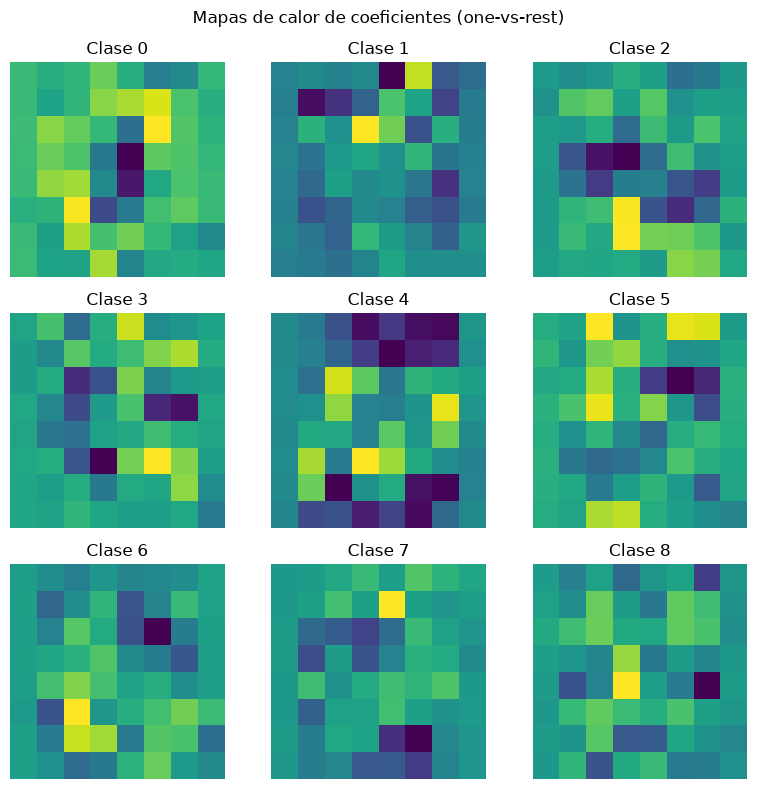


Reporte clasificación (multinomial):
               precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000        45
           1     0.8824    0.9783    0.9278        46
           2     1.0000    0.9773    0.9885        44
           3     0.9583    1.0000    0.9787        46
           4     1.0000    0.9556    0.9773        45
           5     0.9778    0.9565    0.9670        46
           6     1.0000    0.9778    0.9888        45
           7     0.9783    1.0000    0.9890        45
           8     0.9512    0.9070    0.9286        43
           9     0.9773    0.9556    0.9663        45

    accuracy                         0.9711       450
   macro avg     0.9725    0.9708    0.9712       450
weighted avg     0.9723    0.9711    0.9713       450



In [14]:

# Ejercicio 2: MNIST (o fallback a digits)
from sklearn.datasets import fetch_openml, load_digits
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.multiclass import OneVsRestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report
import numpy as np
import matplotlib.pyplot as plt

try:
    mnist = fetch_openml('mnist_784', version=1, as_frame=False)
    X_m = mnist['data'] / 255.0
    y_m = mnist['target'].astype(int)
    dataset_name = "MNIST (fetch_openml)"
except Exception as e:
    print("No fue posible descargar MNIST mediante fetch_openml (probablemente sin conexión). Usando 'digits' como sustituto.")
    digits = load_digits()
    X_m = digits['data'] / 16.0
    y_m = digits['target']
    dataset_name = "digits (fallback a scikit-learn)"

print("Dataset usado:", dataset_name)
# Para acelerar la ejecución en este entorno, tomamos una subsample razonable
n_sample = 3000
if X_m.shape[0] > n_sample:
    rng = np.random.RandomState(0)
    idx = rng.choice(X_m.shape[0], n_sample, replace=False)
    Xs = X_m[idx]
    ys = y_m[idx]
else:
    Xs = X_m
    ys = y_m

# normalizar
scaler = StandardScaler()
Xs_scaled = scaler.fit_transform(Xs)

X_train, X_test, y_train, y_test = train_test_split(Xs_scaled, ys, test_size=0.25, random_state=0, stratify=ys)

# KNN: evaluar varios Ks
ks = [1,3,5,7]
knn_scores = {}
for k in ks:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train, y_train)
    acc = accuracy_score(y_test, knn.predict(X_test))
    knn_scores[k] = acc
print("Resultados KNN (accuracy en test):", knn_scores)

# Logistic Regression: One-vs-Rest
ovr = OneVsRestClassifier(
    LogisticRegression(max_iter=1000)
)
ovr.fit(X_train, y_train)
y_pred_ovr = ovr.predict(X_test)
acc_ovr = accuracy_score(y_test, y_pred_ovr)
print("Accuracy One-vs-Rest (LogReg):", acc_ovr)


multi = LogisticRegression(solver='lbfgs', max_iter=1000)
multi.fit(X_train, y_train)
y_pred_multi = multi.predict(X_test)
acc_multi = accuracy_score(y_test, y_pred_multi)
print("Accuracy Multinomial (LogReg):", acc_multi)

# Visualización: si las entradas tienen formato imagen, mostramos algunos thetas
n_classes = len(np.unique(y_train))
img_side = int(np.sqrt(X_train.shape[1]))
if img_side*img_side == X_train.shape[1]:
    # mostrar mapa de calor de coeficientes (theta) para los primeros 9 clases
    n_show = min(9, n_classes)
    fig, axs = plt.subplots(3,3, figsize=(8,8))
    for i in range(n_show):
        coef = ovr.estimators_[i].coef_[0].reshape(img_side, img_side)
        ax = axs.flat[i]
        im = ax.imshow(coef, aspect='equal')
        ax.set_title(f"Clase {i}")
        ax.axis('off')
    plt.suptitle("Mapas de calor de coeficientes (one-vs-rest)")
    plt.tight_layout()
    plt.show()

print("\nReporte clasificación (multinomial):\n", classification_report(y_test, multi.predict(X_test), digits=4))
